# Regresi Polinomial

Course 2: Supervised Learning

Regresi linear hanya bisa menangkap hubungan berbentuk garis lurus. Kalau hubungannya melengkung, kita bisa menambahkan pangkat dari fitur (kuadrat, kubik, dan seterusnya) sebagai fitur baru, lalu tetap memakai model linear. Itulah regresi polinomial.

Di notebook ini saya mencoba polinomial pada satu fitur dan banyak fitur, melihat gejala overfitting, lalu mencari derajat polinomial terbaik dengan `GridSearchCV`.

## Dataset

Datanya `encoded_car_data.csv`, harga mobil beserta spesifikasi teknisnya, yang sudah dibersihkan dan di-encode. Targetnya kolom `price`. Dibaca langsung dari link:

https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-ML240EN-SkillsNetwork/labs/encoded_car_data.csv

## 1. Import dan baca data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline

sns.set_style("whitegrid")

In [2]:
URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-ML240EN-SkillsNetwork/labs/encoded_car_data.csv"
data = pd.read_csv(URL)
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 36 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   diesel       205 non-null    float64
 1   gas          205 non-null    float64
 2   std          205 non-null    float64
 3   turbo        205 non-null    float64
 4   convertible  205 non-null    float64
 5   hardtop      205 non-null    float64
 6   hatchback    205 non-null    float64
 7   sedan        205 non-null    float64
 8   wagon        205 non-null    float64
 9   4wd          205 non-null    float64
 10  fwd          205 non-null    float64
 11  rwd          205 non-null    float64
 12  dohc         205 non-null    float64
 13  dohcv        205 non-null    float64
 14  l            205 non-null    float64
 15  ohc          205 non-null    float64
 16  ohcf         205 non-null    float64
 17  ohcv         205 non-null    float64
 18  rotor        205 non-null    float64
 19  eight   

## 2. Lihat bentuk hubungan fitur dengan harga

`lmplot` dengan `order=2` menggambar kurva kuadrat, jadi kelihatan apakah hubungannya lebih cocok melengkung.

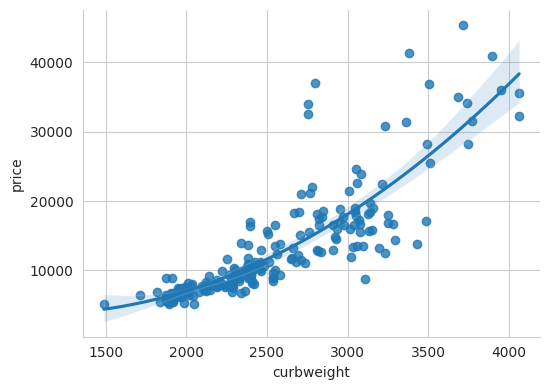

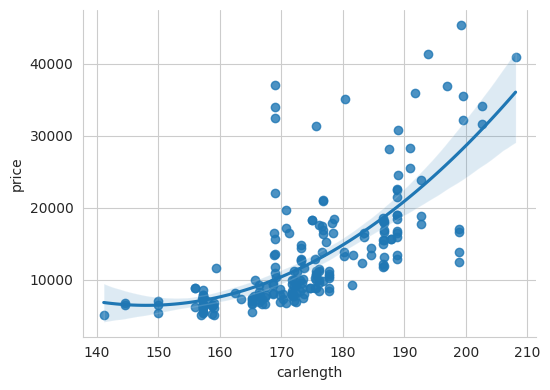

In [3]:
sns.lmplot(x="curbweight", y="price", data=data, order=2, height=4, aspect=1.4)
sns.lmplot(x="carlength", y="price", data=data, order=2, height=4, aspect=1.4)
plt.show()

### Latihan 1: `horsepower` vs `price`

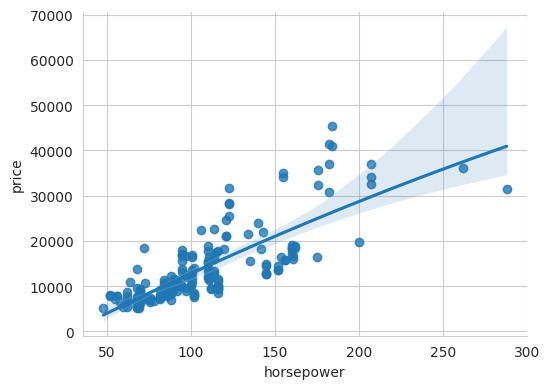

In [4]:
sns.lmplot(x="horsepower", y="price", data=data, order=2, height=4, aspect=1.4)
plt.show()

## 3. Siapkan data

In [5]:
X = data.drop(columns="price")
y = data["price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print("data train:", X_train.shape[0], "| data test:", X_test.shape[0])

data train: 143 | data test: 62


Dua fungsi bantu yang akan dipakai berulang: satu untuk membandingkan sebaran harga aktual dengan prediksi, satu lagi untuk menghitung $R^2$ tiap fitur secara terpisah (model dilatih dengan satu fitur saja).

In [6]:
def plot_sebaran(aktual, prediksi):
    plt.figure(figsize=(7, 4))
    sns.kdeplot(aktual, color="red", label="Aktual")
    sns.kdeplot(prediksi, color="blue", label="Prediksi")
    plt.xlabel("Harga")
    plt.title("Sebaran harga aktual vs prediksi")
    plt.legend()
    plt.show()


def r2_per_fitur(model, kecuali=()):
    fitur = [f for f in X.columns if f not in kecuali]
    r2_tr, r2_te = [], []
    for f in fitur:
        model.fit(X_train[[f]], y_train)
        r2_tr.append(model.score(X_train[[f]], y_train))
        r2_te.append(model.score(X_test[[f]], y_test))

    hasil = pd.DataFrame({"train": r2_tr, "test": r2_te}, index=fitur)
    ax = hasil.plot.bar(figsize=(12, 4), width=0.8)
    ax.set_ylim(-1, 1)  # nilai yang sangat negatif dipotong supaya grafik tetap terbaca
    ax.set_ylabel("R2")
    plt.show()

    terlalu_jelek = hasil.index[hasil["test"] < -1].tolist()
    if terlalu_jelek:
        print("R2 test di bawah -1 (terpotong di grafik):", terlalu_jelek)
    print(hasil.agg(["mean", "max"]).round(3))
    return hasil

## 4. Regresi linear biasa sebagai pembanding

### Semua fitur sekaligus

R2 train: 0.9263
R2 test : 0.8471


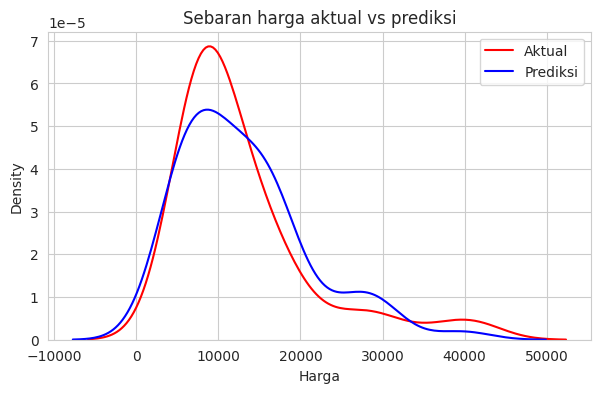

In [7]:
lm = LinearRegression().fit(X_train, y_train)
print("R2 train:", round(lm.score(X_train, y_train), 4))
print("R2 test :", round(lm.score(X_test, y_test), 4))
plot_sebaran(y_test, lm.predict(X_test))

In [8]:
koef = pd.Series(lm.coef_, index=X.columns).sort_values(key=abs, ascending=False)
koef.head(10).round(1)

,0
dohcv,-13286.5
eight,9218.4
ohcf,6068.8
four,-5338.4
ohc,4642.4
hardtop,3165.5
ohcv,-2820.0
five,-2742.7
wagon,-2493.6
dohc,2467.0


Koefisien terbesar tidak selalu berarti fitur paling penting, karena skala tiap fitur berbeda-beda (misalnya satuan berat vs jumlah silinder). Karena itu aku lihat juga performa tiap fitur secara individual.

### Satu fitur per model

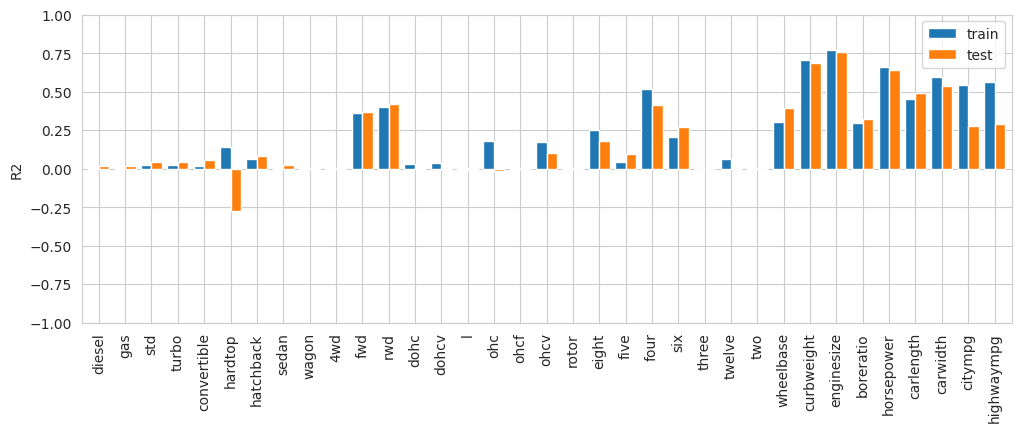

      train   test
mean  0.212  0.177
max   0.769  0.753


In [9]:
hasil_linear = r2_per_fitur(LinearRegression())

### Latihan 2: regresi linear dengan `StandardScaler` (semua fitur)

R2 train: 0.9263
R2 test : 0.8419


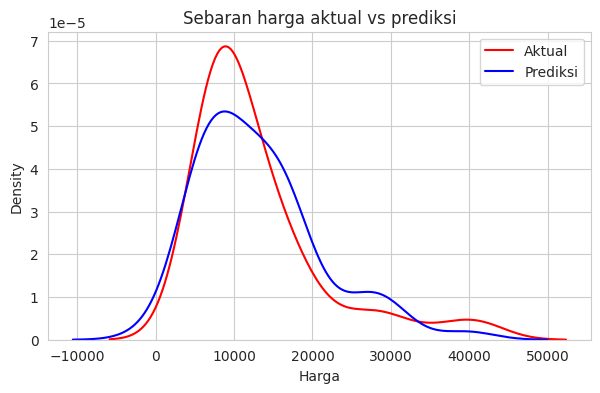

In [10]:
pipa_ss = Pipeline([("ss", StandardScaler()), ("lr", LinearRegression())])
pipa_ss.fit(X_train, y_train)

print("R2 train:", round(pipa_ss.score(X_train, y_train), 4))
print("R2 test :", round(pipa_ss.score(X_test, y_test), 4))
plot_sebaran(y_test, pipa_ss.predict(X_test))

### Latihan 3: pipeline dengan `StandardScaler` untuk tiap fitur

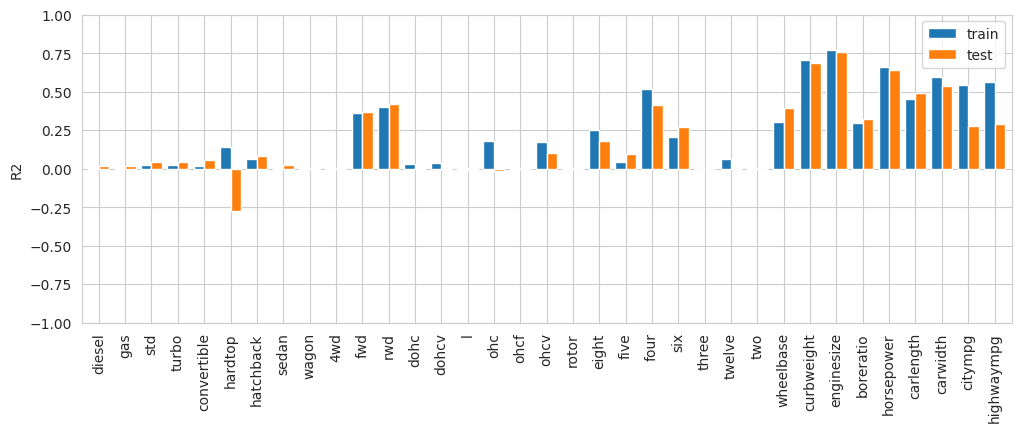

      train   test
mean  0.212  0.177
max   0.769  0.753


In [11]:
hasil_ss = r2_per_fitur(Pipeline([("ss", StandardScaler()), ("lr", LinearRegression())]))

## 5. Fitur polinomial

### Semua fitur, derajat 2

`PolynomialFeatures(degree=2)` menambahkan kuadrat setiap fitur dan perkalian antar pasangan fitur. Aku pakai `include_bias=False` karena `LinearRegression` sudah punya intercept sendiri.

In [12]:
poly = PolynomialFeatures(degree=2, include_bias=False)
Xtr_poly = poly.fit_transform(X_train)
Xte_poly = poly.transform(X_test)

print("jumlah fitur sebelum:", X_train.shape[1])
print("jumlah fitur sesudah:", Xtr_poly.shape[1])

jumlah fitur sebelum: 35
jumlah fitur sesudah: 665


In [13]:
lm_poly = LinearRegression().fit(Xtr_poly, y_train)
print("R2 train:", round(lm_poly.score(Xtr_poly, y_train), 4))
print("R2 test :", round(lm_poly.score(Xte_poly, y_test), 4))

R2 train: 0.9985
R2 test : -36729.9579


Jumlah fitur melonjak jauh melebihi jumlah data latih. $R^2$ train yang sangat tinggi dengan $R^2$ test yang jauh lebih rendah (bahkan bisa negatif) adalah tanda khas overfitting: model menghafal data latih.

### Satu fitur per model, derajat 2

In [14]:
pipa_poly = Pipeline([
    ("polynomial", PolynomialFeatures(degree=2, include_bias=False)),
    ("model", LinearRegression()),
])
pipa_poly.fit(X_train, y_train)
print("R2 train:", round(pipa_poly.score(X_train, y_train), 4))
print("R2 test :", round(pipa_poly.score(X_test, y_test), 4))

R2 train: 0.9985
R2 test : -36729.9579


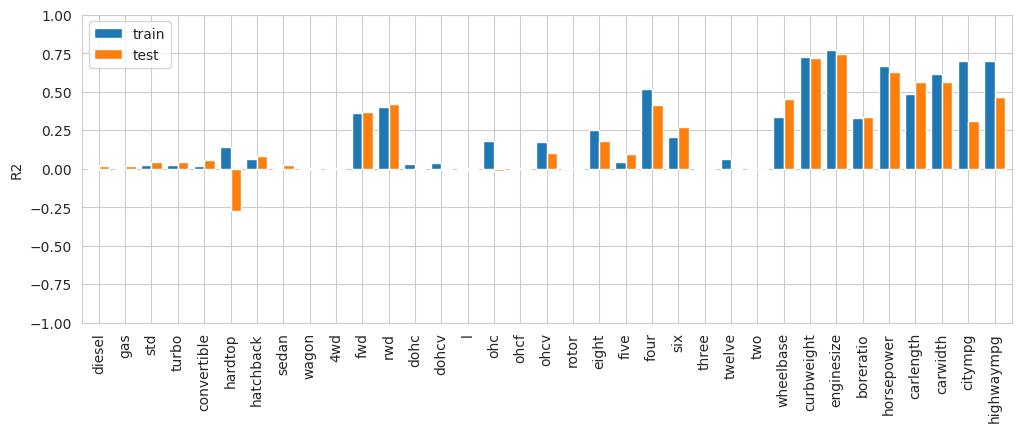

      train   test
mean  0.224  0.188
max   0.771  0.746


In [15]:
hasil_poly = r2_per_fitur(pipa_poly)

Perbandingan dengan hasil linear di atas: kalau nilai R2 maksimum dan rata-rata test naik, berarti hubungan fitur tunggal dengan harga memang cenderung melengkung.

## 6. GridSearchCV untuk memilih derajat

Derajat polinomial adalah hyperparameter yang harus dipilih. `GridSearchCV` mencoba setiap kandidat dengan cross-validation (default 5 lipatan). Penting: pencarian dilakukan hanya di **data train**. Kalau dicari di data test, hasil akhirnya jadi terlalu optimis karena test sudah ikut dipakai untuk memilih model.

Nama parameter di dalam pipeline ditulis `namalangkah__parameter`.

In [16]:
pipa = Pipeline([
    ("polynomial", PolynomialFeatures(include_bias=False)),
    ("scaler", StandardScaler()),
    ("model", LinearRegression()),
])

grid = GridSearchCV(pipa, {"polynomial__degree": [1, 2, 3]}, cv=5)
grid.fit(X_train, y_train)

pd.DataFrame(grid.cv_results_)[["param_polynomial__degree", "mean_test_score", "std_test_score"]]

,param_polynomial__degree,mean_test_score,std_test_score
0,1,7.791618e-01,1.085991e-01
1,2,-6.624621e+02,6.054035e+02
2,3,-1.136607e+06,1.873851e+06


parameter terbaik: {'polynomial__degree': 1}
R2 train: 0.9263
R2 test : 0.8419


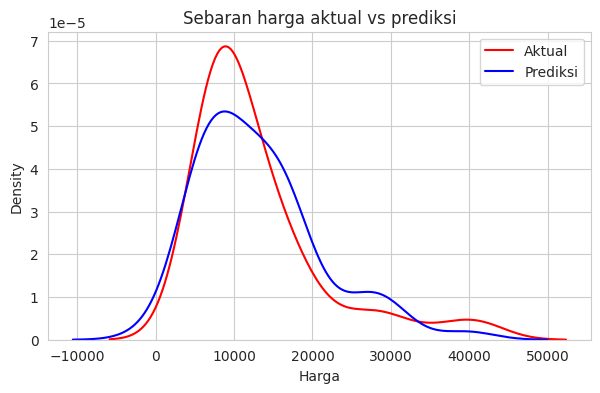

In [17]:
terbaik = grid.best_estimator_
print("parameter terbaik:", grid.best_params_)
print("R2 train:", round(terbaik.score(X_train, y_train), 4))
print("R2 test :", round(terbaik.score(X_test, y_test), 4))
plot_sebaran(y_test, terbaik.predict(X_test))

Nilai $R^2$ test inilah yang dipakai untuk menilai model, bukan skor cross-validation di train, karena data test tidak pernah dipakai selama pemilihan.

### Latihan 4: GridSearchCV untuk setiap fitur

Untuk tiap fitur dicari derajat (1 sampai 5) dan opsi `positive` (koefisien dipaksa tidak negatif atau tidak) yang terbaik.

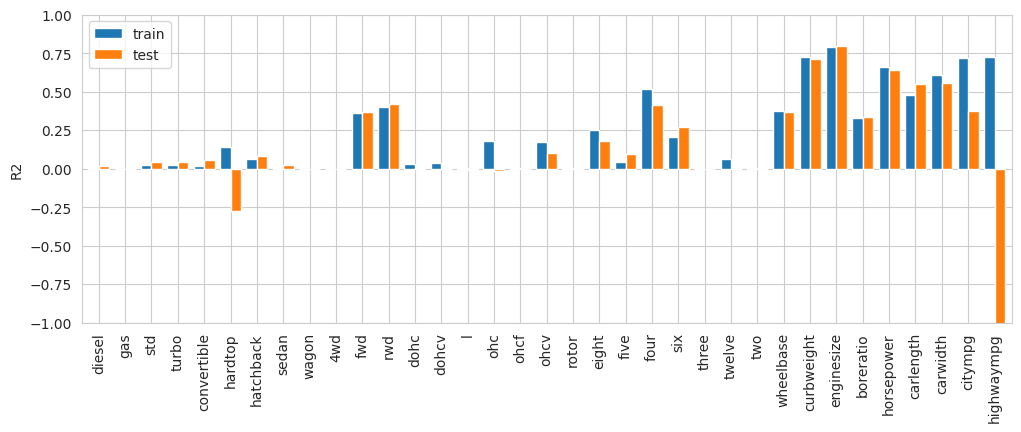

      train   test
mean  0.227  0.133
max   0.787  0.798


In [18]:
param_fitur = {
    "polynomial__degree": [1, 2, 3, 4, 5],
    "model__positive": [True, False],
}

r2_tr, r2_te = [], []
for f in X.columns:
    pipa_f = Pipeline([
        ("polynomial", PolynomialFeatures(include_bias=False)),
        ("model", LinearRegression()),
    ])
    cari = GridSearchCV(pipa_f, param_fitur, cv=5)
    cari.fit(X_train[[f]], y_train)
    r2_tr.append(cari.best_estimator_.score(X_train[[f]], y_train))
    r2_te.append(cari.best_estimator_.score(X_test[[f]], y_test))

hasil_grid = pd.DataFrame({"train": r2_tr, "test": r2_te}, index=X.columns)
ax = hasil_grid.plot.bar(figsize=(12, 4), width=0.8)
ax.set_ylim(-1, 1)
ax.set_ylabel("R2")
plt.show()
print(hasil_grid.agg(["mean", "max"]).round(3))

Kalau dibandingkan dengan hasil per fitur sebelumnya, terlihat apakah memilih derajat dan opsi `positive` lewat cross-validation memperbaiki performa di data test.